In [264]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from tqdm import tqdm
import os
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from matplotlib.legend_handler import HandlerBase

In [148]:
names = locals()

In [182]:
df_cement_production = pd.read_csv('../data/production-142.csv', index_col=0)
economies_142 = df_cement_production.columns.tolist()

In [169]:
DF_country.loc[2022, 'S_coarse_annual'] / 1e3

np.float64(199.23192)

In [271]:
for country in tqdm(economies_142):
    names[f'DF_{country}'] = pd.read_excel(f'../results/material-flows/historical/{country}.xlsx', sheet_name='50', index_col=0)
    names[f'DF_{country}_025'] = pd.read_excel(f'../results/material-flows/historical/{country}.xlsx', sheet_name='2.3', index_col=0)
    names[f'DF_{country}_975'] = pd.read_excel(f'../results/material-flows/historical/{country}.xlsx', sheet_name='97.7', index_col=0)

100%|██████████| 142/142 [00:50<00:00,  2.79it/s]


In [282]:
def draw_historical_for_a_country(material, country, ax1):
    DF_country = names[f'DF_{country}']
    DF_country_025 = names[f'DF_{country}_025']
    DF_country_975 = names[f'DF_{country}_975'] 

    gg_dict = dict({'gravel': 'S_coarse_annual', 'sand': 'S_fine_annual', 'limestone': 'S_binder_annual'})
    hh = gg_dict[material]
    scale_dict = dict({'Gt': 1e-6, 'Mt': 1e-3, 'kt': 1})
    idx = np.argmax(DF_country_975[[f'{material}_extraction', f'{material}_export', f'{material}_import']].max())
    the_max_1_ = DF_country_975[[f'{material}_extraction', f'{material}_export', f'{material}_import']].max().max() / 1e6
    the_max_2_ = DF_country_975[[hh]].max().max() / 1e6

    if the_max_1_ <= .1:
        yaxis_scale_1 = 'Mt'
        if the_max_1_ <= 0.0001:
            yaxis_scale_1 = 'kt'
    else:
        yaxis_scale_1 = 'Gt'

    if the_max_2_ <= .1:
        yaxis_scale_2 = 'Mt'
        if the_max_2_ <= 0.001:
            yaxis_scale_2 = 'kt'
    else:
        yaxis_scale_2 = 'Gt'

    scale_factor_1 = scale_dict[yaxis_scale_1]
    scale_factor_2 = scale_dict[yaxis_scale_2]
    the_max_1 = the_max_1_ * 1e6 * scale_factor_1 * 2
    the_max_2 = the_max_2_ * 1e6 * scale_factor_2 * 1.1


    ax1_1 = ax1.twinx()
    (DF_country * scale_factor_2).plot(y=[hh], color='grey', label=['material stock'], legend=False, zorder=1, ax=ax1)
    # (DF_country * scale_factor_2).plot(y=['S_fine_annual'], color='r', legend=False, zorder=1, ax=ax1)
    (DF_country * scale_factor_1).plot(y=[f'{material}_extraction'], label=['extraction'], zorder=2, legend=False, ax=ax1_1)
    (DF_country * scale_factor_1).plot(y=[f'{material}_export', f'{material}_import'], color=['g', 'r'], zorder=2,  label=['export', 'import'], legend=False, ax=ax1_1)
    ax1.fill_between(np.linspace(1931, 2022, 92), (DF_country_025 * scale_factor_2)[hh], (DF_country_975 * scale_factor_2)[hh], color='lightgrey', alpha=0.7, lw=0, zorder=0)
    ax1_1.fill_between(np.linspace(1931, 2022, 92), (DF_country_025 * scale_factor_1)[f'{material}_extraction'], (DF_country_975 * scale_factor_1)[f'{material}_extraction'], alpha=0.3, zorder=0)
    ax1_1.fill_between(np.linspace(1931, 2022, 92), (DF_country_025 * scale_factor_1)[f'{material}_export'], (DF_country_975 * scale_factor_1)[f'{material}_export'], color='lightgreen', alpha=0.7, zorder=0)
    ax1_1.fill_between(np.linspace(1931, 2022, 92), (DF_country_025 * scale_factor_1)[f'{material}_import'], (DF_country_975 * scale_factor_1)[f'{material}_import'], color='pink', alpha=0.7, zorder=0)

    ax1.set_xlim(1931, 2022)
    ax1.set_ylim(0, the_max_2)
    ax1_1.set_ylim(0, the_max_1)
    ax1.grid('on', ls='--')
    ax1.set_xticks([1931, 1960, 1990, 2022])
    ax1.set_ylabel(yaxis_scale_2, color='grey',)
    color_list = ['tab:blue', 'g', 'r']
    ax1_1.set_ylabel(f'{yaxis_scale_1} per year', color=color_list[idx])
    ax1.set_title(country)
    ax1.tick_params(axis='y', colors='dimgrey')
    ax1_1.tick_params(axis='y', colors=color_list[idx])

    # plt.show()

In [245]:
# -------- 1) 定义 handler（先定义！） --------
class HandlerLineWithBand(HandlerBase):
    def __init__(self, band_scale=0.8, **kwargs):
        super().__init__(**kwargs)
        self.band_scale = band_scale   # 阴影在 legend 小框里占的高度比例

    def create_artists(self, legend, orig_handle,
                       xdescent, ydescent, width, height, fontsize, trans):
        line, band = orig_handle  # (Line2D, Rectangle)
        bh = self.band_scale * height
        by = ydescent + (height - bh) / 2.0  # 居中放带

        band_art = Rectangle((xdescent, by), width, bh,
                             facecolor=band.get_facecolor(),
                             edgecolor='none',
                             alpha=band.get_alpha(),
                             transform=trans)
        line_art = Line2D([xdescent, xdescent + width],
                          [ydescent + 0.5*height, ydescent + 0.5*height],
                          color=line.get_color(),
                          linestyle=line.get_linestyle(),
                          linewidth=line.get_linewidth(),
                          transform=trans)
        return [band_art, line_art]

# -------- 2) 组装你的 legend 句柄 --------
# 线（与图中一致的样式）
ex_line = Line2D([], [], color='#1f77b4', lw=2.0, ls='-')
st_line = Line2D([], [], color='0.4',     lw=2.0, ls='-')

# 阴影代理（与图中 fill_between 一致的颜色与 alpha）
ex_band = Rectangle((0,0), 1, 1, facecolor='#1f77b4', alpha=0.35)
st_band = Rectangle((0,0), 1, 1, facecolor='0.5',     alpha=0.25)

# 关键：必须是“元组”
ex_handle = (ex_line, ex_band)
st_handle = (st_line, st_band)

# 其它普通线
im_handle   = Line2D([], [], color='r', lw=1.8, ls='-')
expt_handle = Line2D([], [], color='g', lw=1.8, ls='-')

handles = [st_handle, ex_handle, im_handle, expt_handle]
labels  = ['material stock (95% CI)', 'extraction (95% CI)', 'import', 'export']

In [284]:
# 1) 自定义 handler：可调“带厚度”和左右留白，保证线与带等长
class HandlerLineWithBand(HandlerBase):
    def __init__(self, band_scale=0.85, pad_frac=0.10, **kwargs):
        """
        band_scale:  阴影带在 legend 小框里的相对高度(0~1)
        pad_frac:    左右留白比例，避免贴边；同时保证线和带同样长度
        """
        super().__init__(**kwargs)
        self.band_scale = band_scale
        self.pad_frac = pad_frac

    def create_artists(self, legend, orig_handle,
                       xdescent, ydescent, width, height, fontsize, trans):
        line, band = orig_handle

        # 统一左右留白，线和带用同一长度
        x0 = xdescent + self.pad_frac * width
        x1 = xdescent + (1 - self.pad_frac) * width
        w  = x1 - x0

        # 带：竖直方向居中
        bh = self.band_scale * height
        by = ydescent + (height - bh) / 2.0
        band_art = Rectangle((x0, by), w, bh,
                             facecolor=band.get_facecolor(),
                             edgecolor='none',
                             alpha=band.get_alpha(),
                             transform=trans)

        # 线：与带等长；linecap 设为 'butt' 防止两端外伸
        line_art = Line2D([x0, x1], [ydescent + 0.5*height]*2,
                          color=line.get_color(),
                          linestyle=line.get_linestyle(),
                          linewidth=line.get_linewidth(),
                          solid_capstyle='butt',
                          transform=trans)
        return [band_art, line_art]


# 2) 小工具：生成“线+带”的句柄（颜色/线宽/alpha 与图中一致）
def make_line_band(color, lw=2.0, ls='-', alpha=0.30):
    line = Line2D([], [], color=color, lw=lw, ls=ls, solid_capstyle='butt')
    band = Rectangle((0, 0), 1, 1, facecolor=color, alpha=alpha)  # 只取颜色/alpha
    return (line, band)

# material stock（灰）
st_handle = make_line_band(color='0.4', lw=2.0, alpha=0.25)
# extraction（蓝）
ex_handle = make_line_band(color='#1f77b4', lw=2.0, alpha=0.35)
# import（红）——若无实际CI，仅作视觉匹配可用更浅 alpha
im_handle = make_line_band(color='r', lw=1.8, alpha=0.18)
# export（绿）
expt_handle = make_line_band(color='g', lw=1.8, alpha=0.18)

handles = [st_handle, ex_handle, im_handle, expt_handle]
labels  = ['in-use stock (95% CI)', 'extraction (95% CI)', 'import (95% CI)', 'export (95% CI)']

  0%|          | 0/5 [00:00<?, ?it/s]

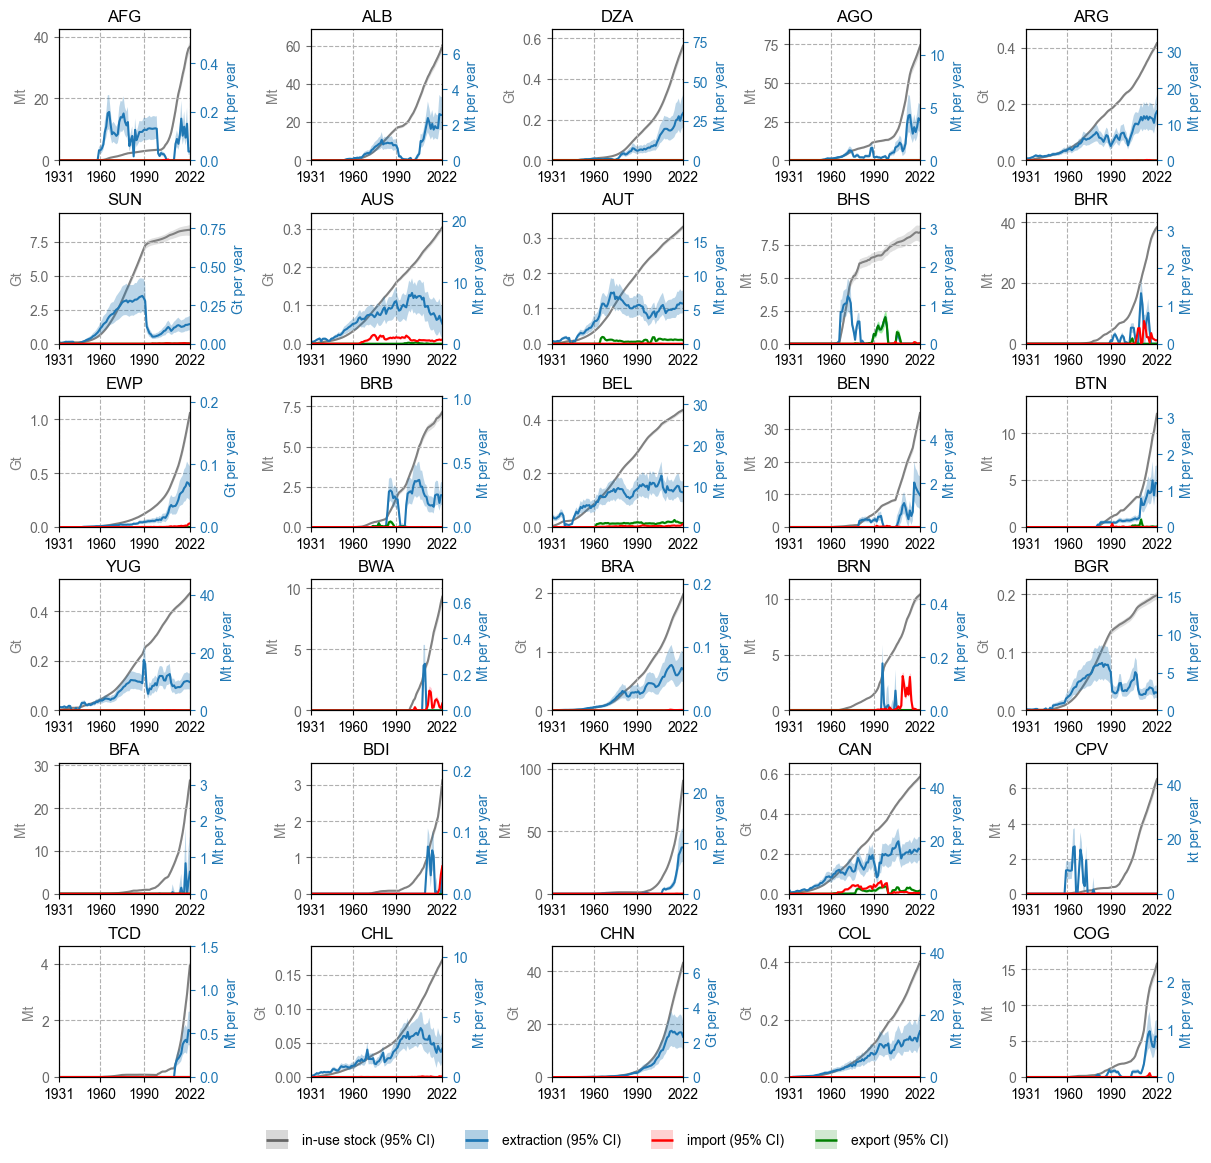

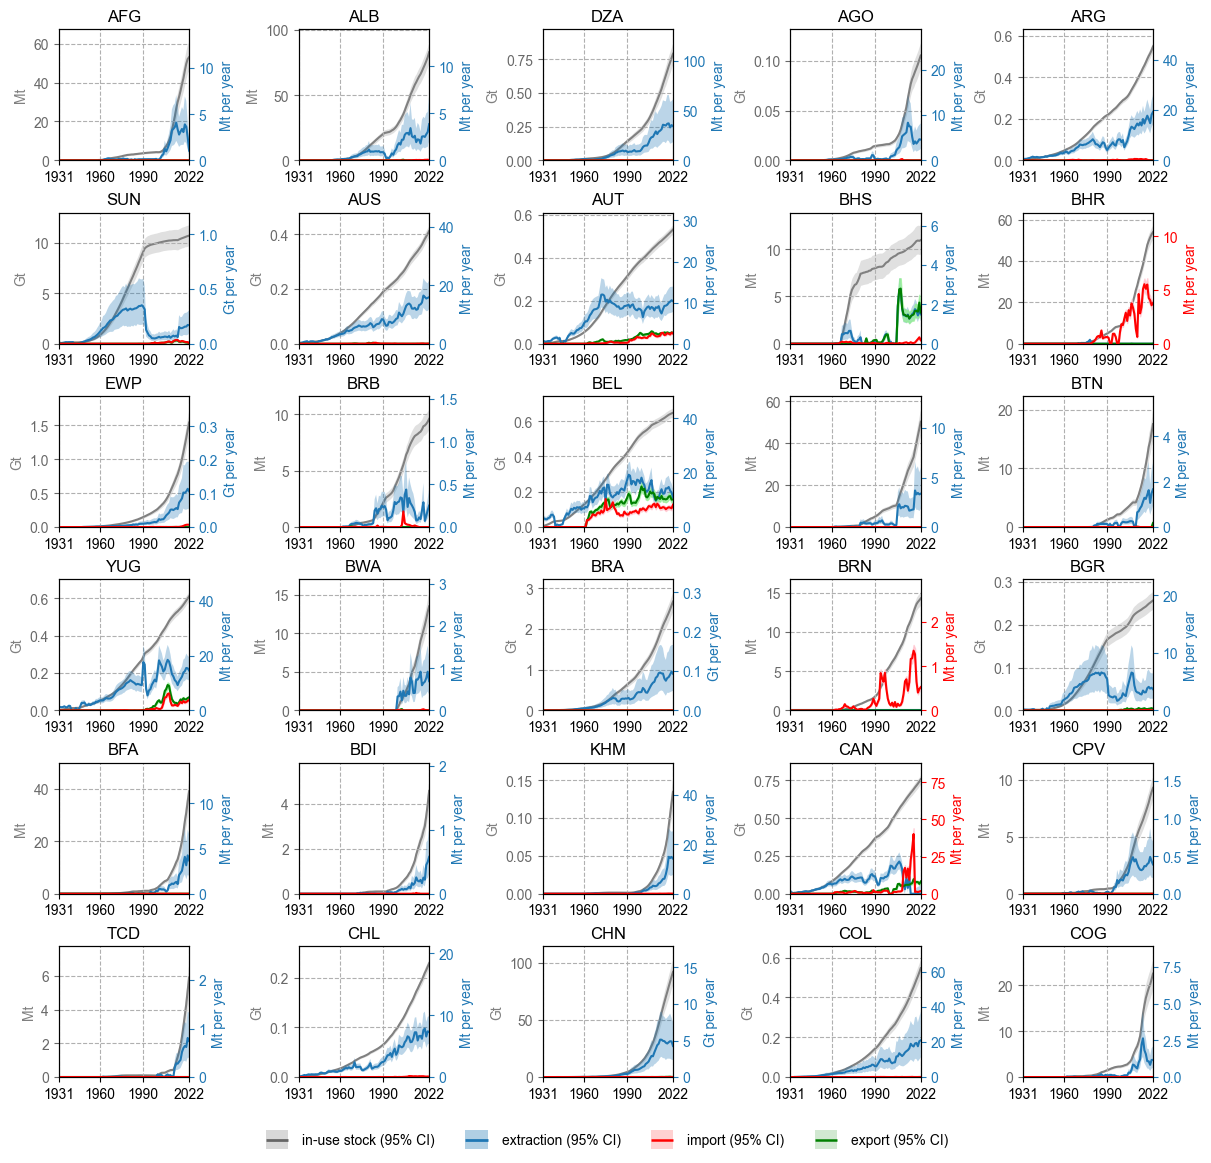

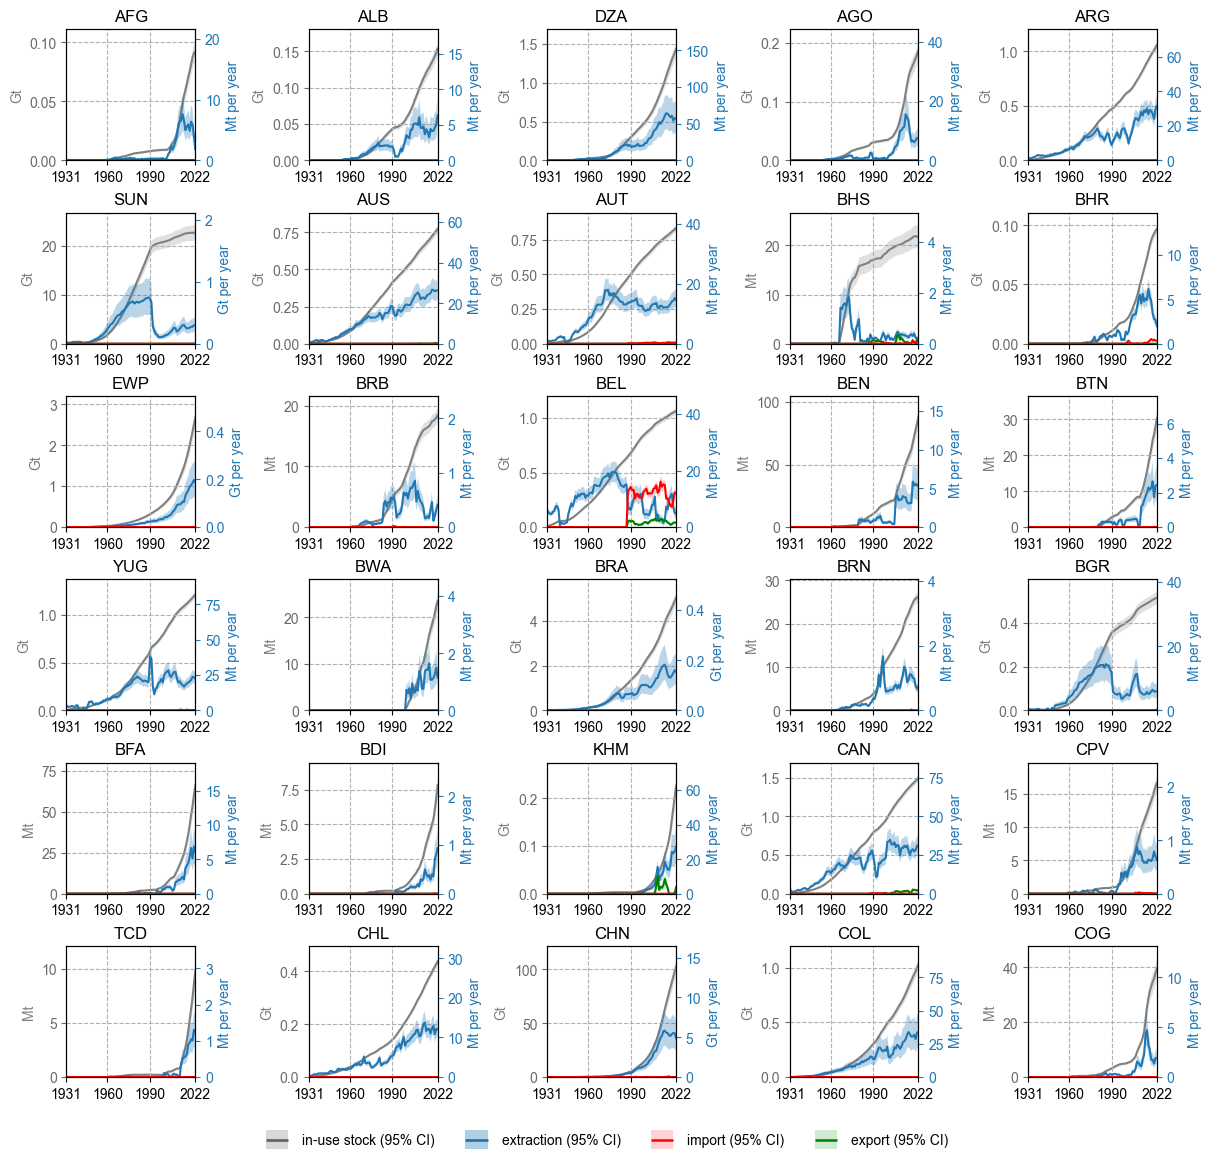

 20%|██        | 1/5 [00:17<01:11, 17.99s/it]

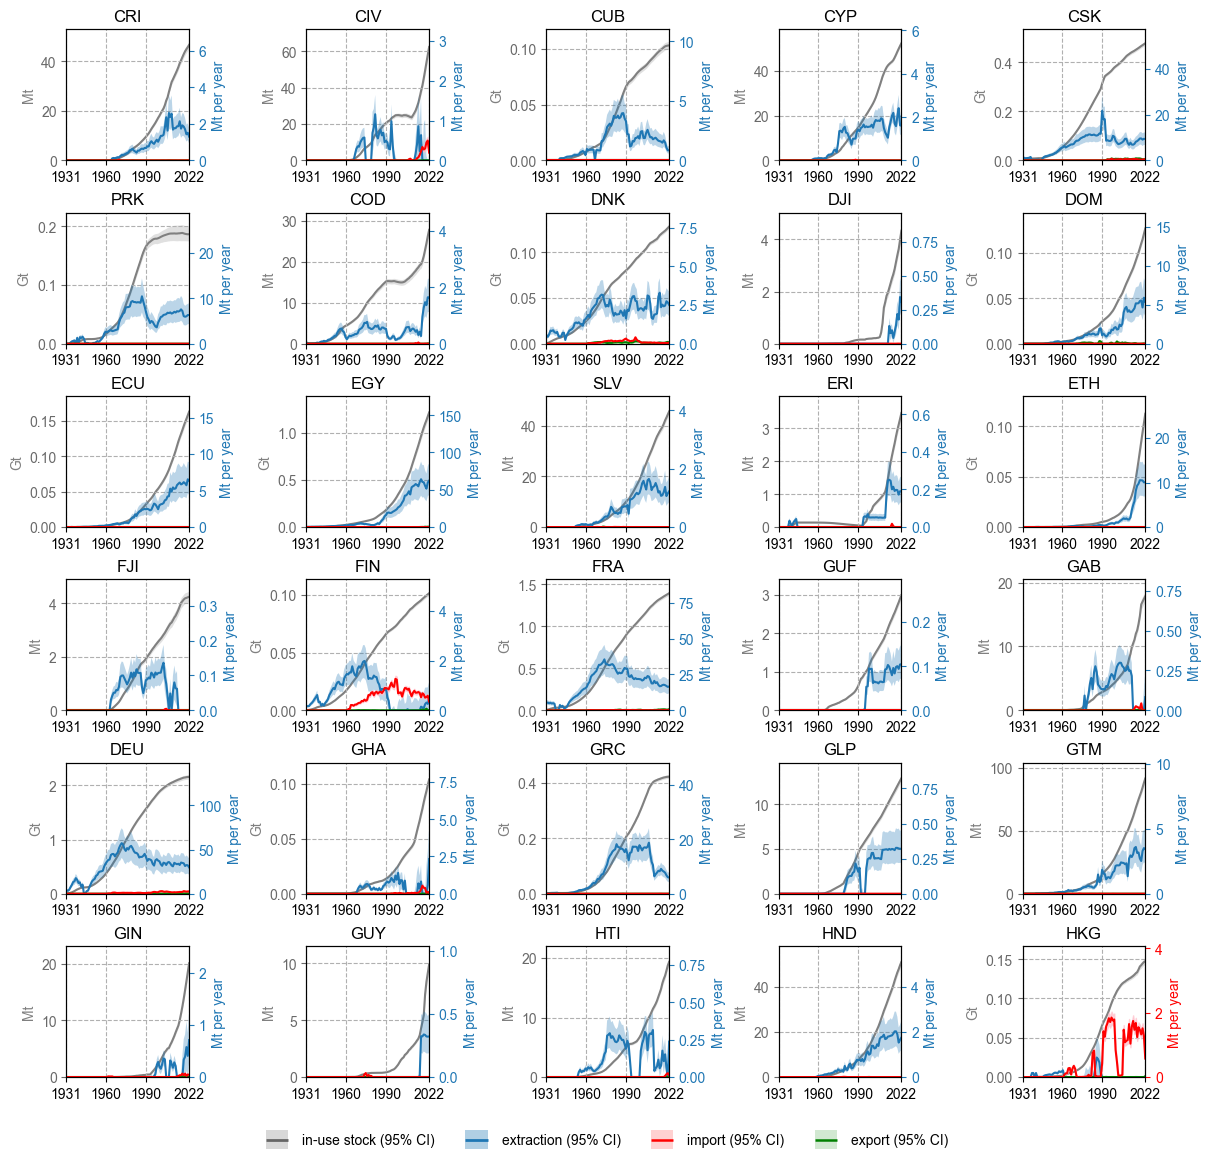

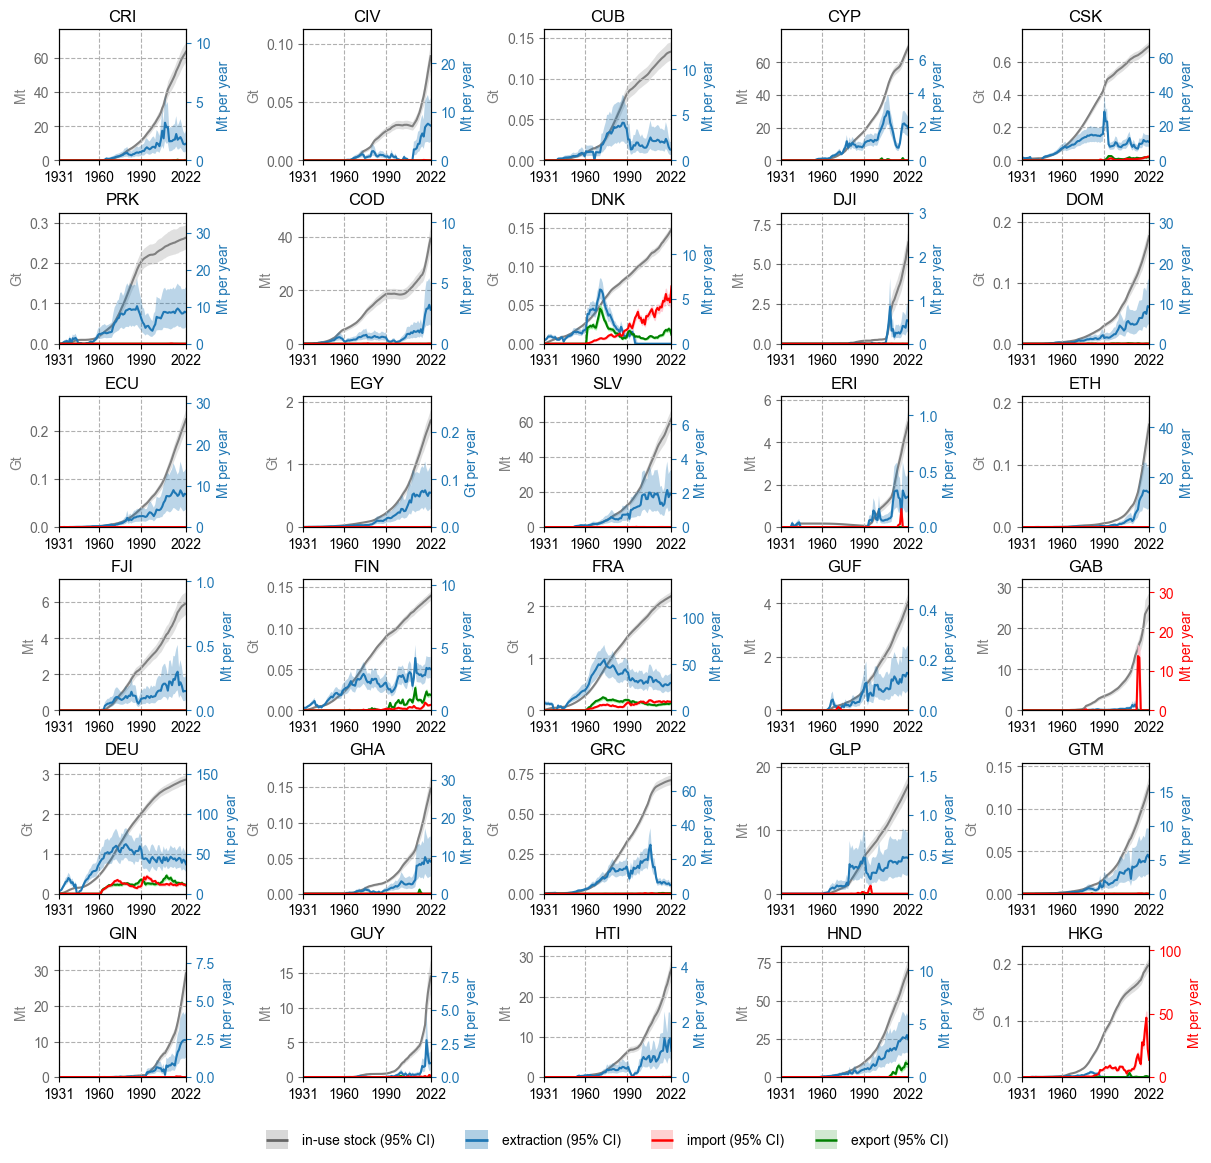

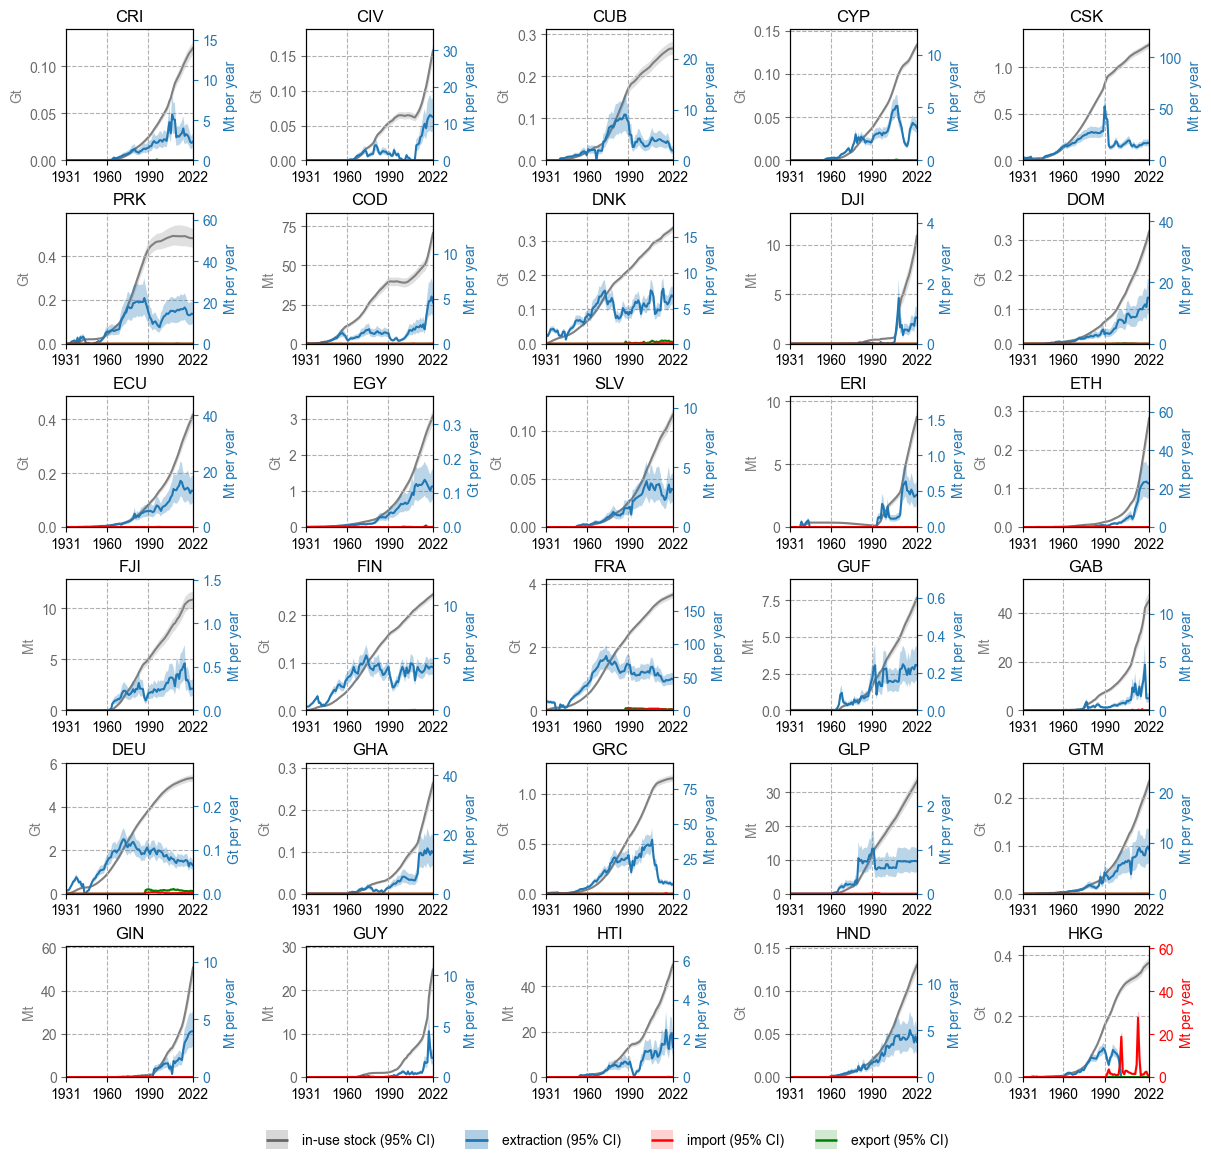

 40%|████      | 2/5 [00:35<00:52, 17.61s/it]

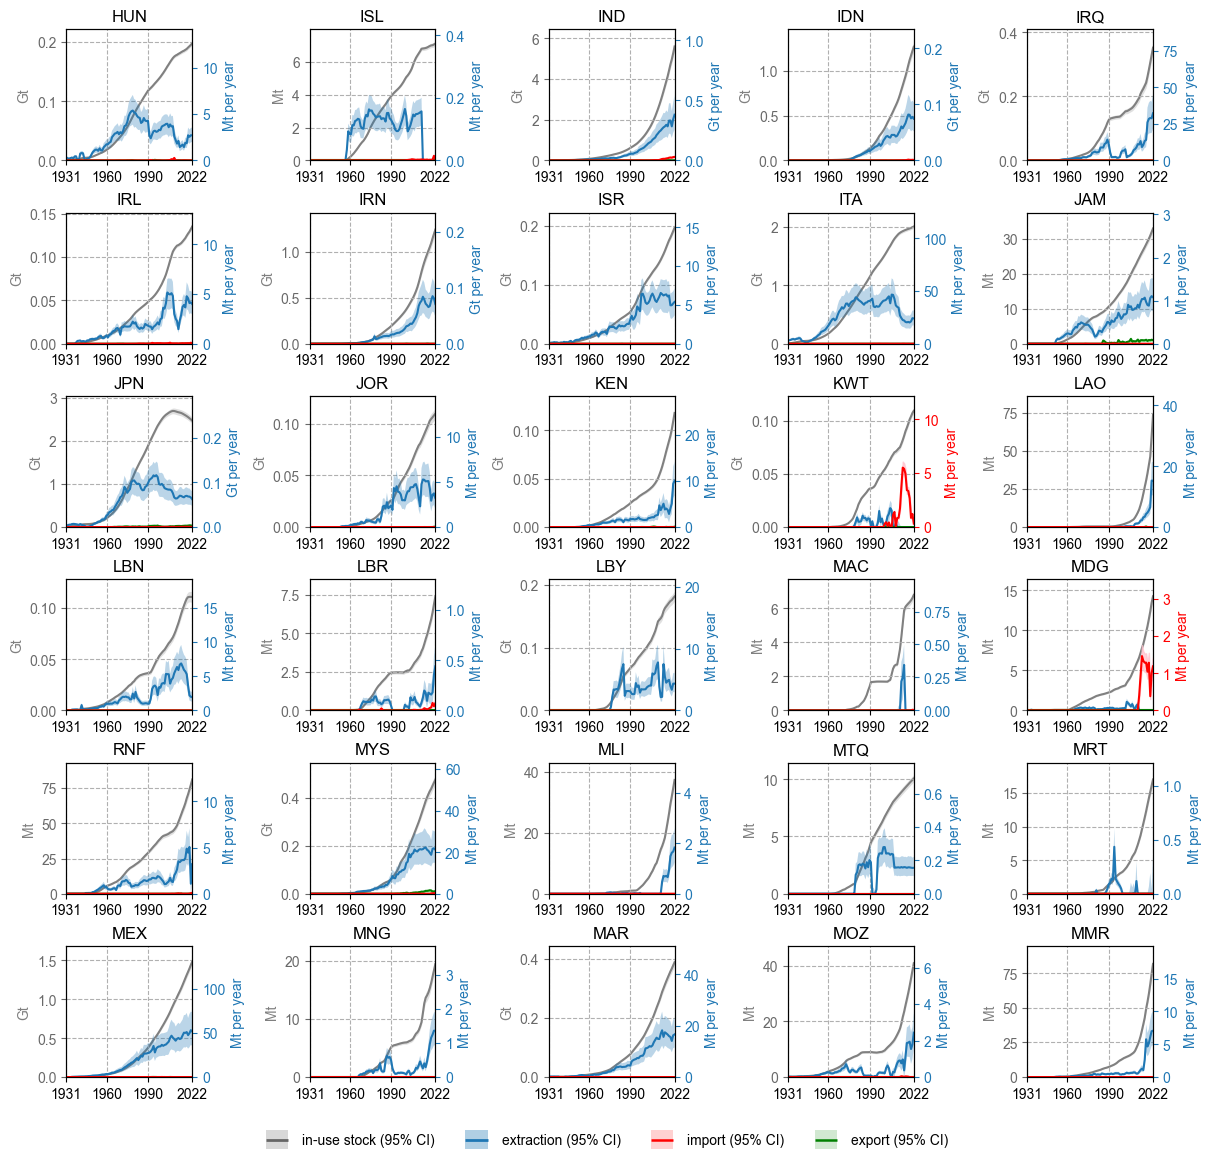

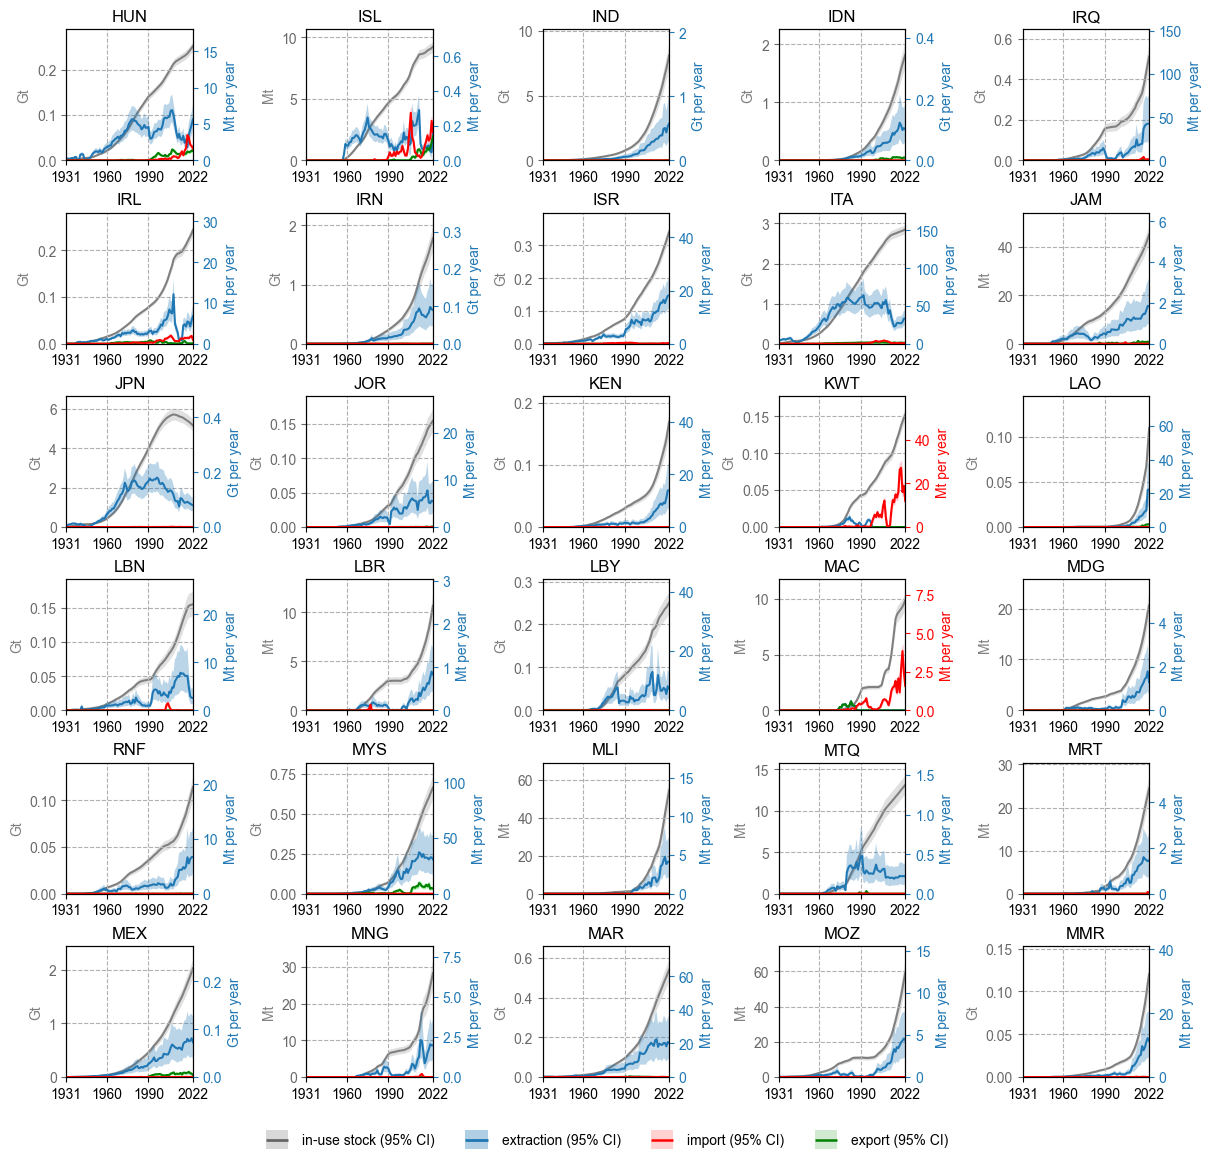

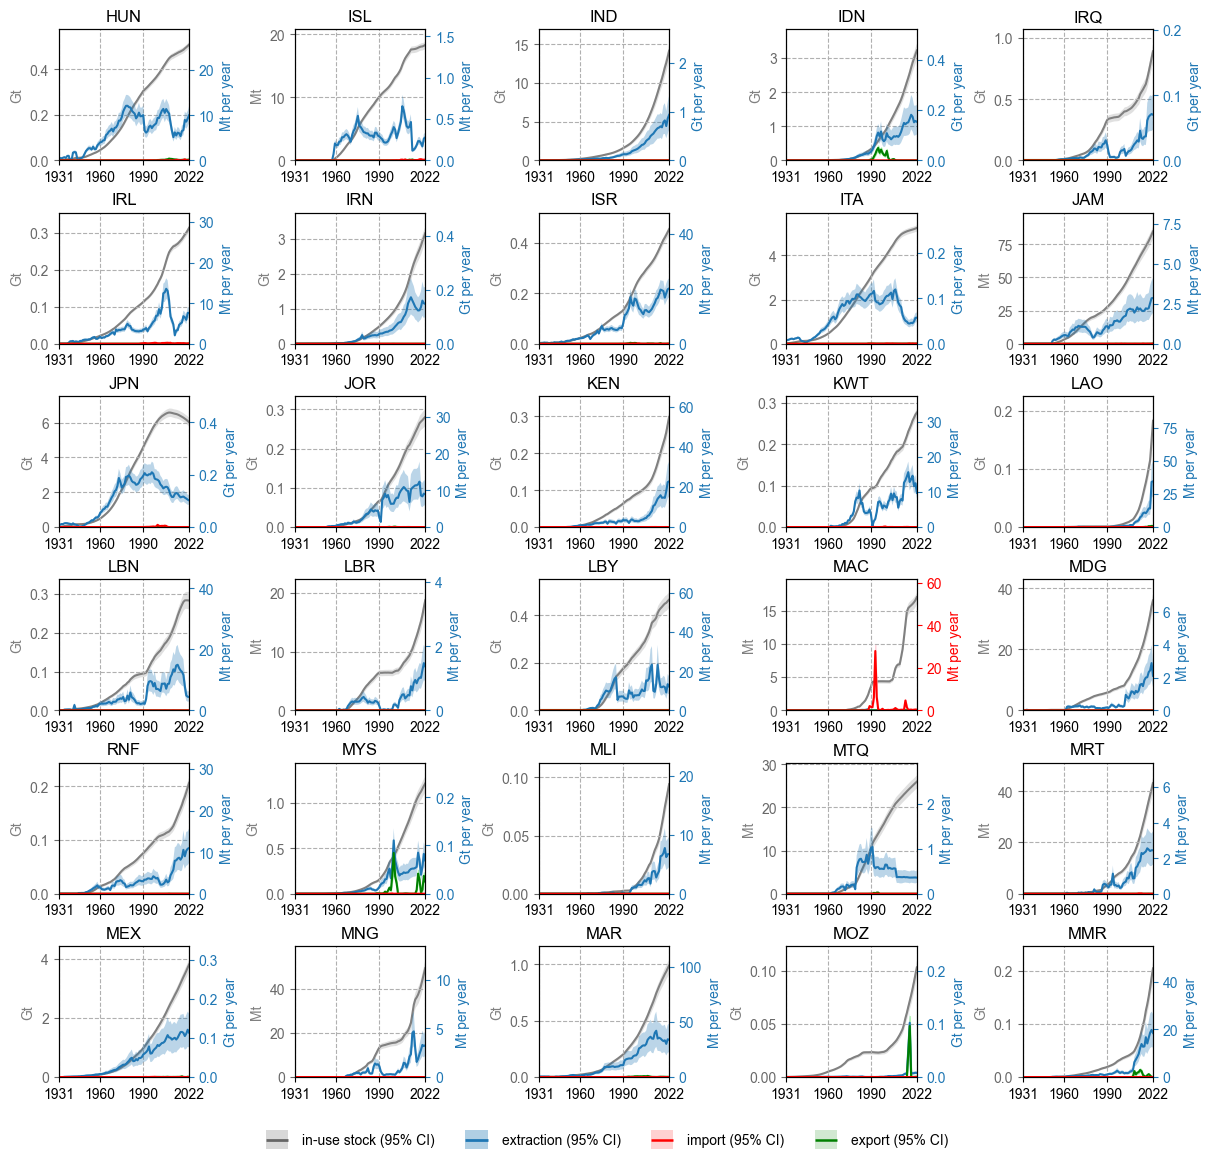

 60%|██████    | 3/5 [00:53<00:35, 17.82s/it]

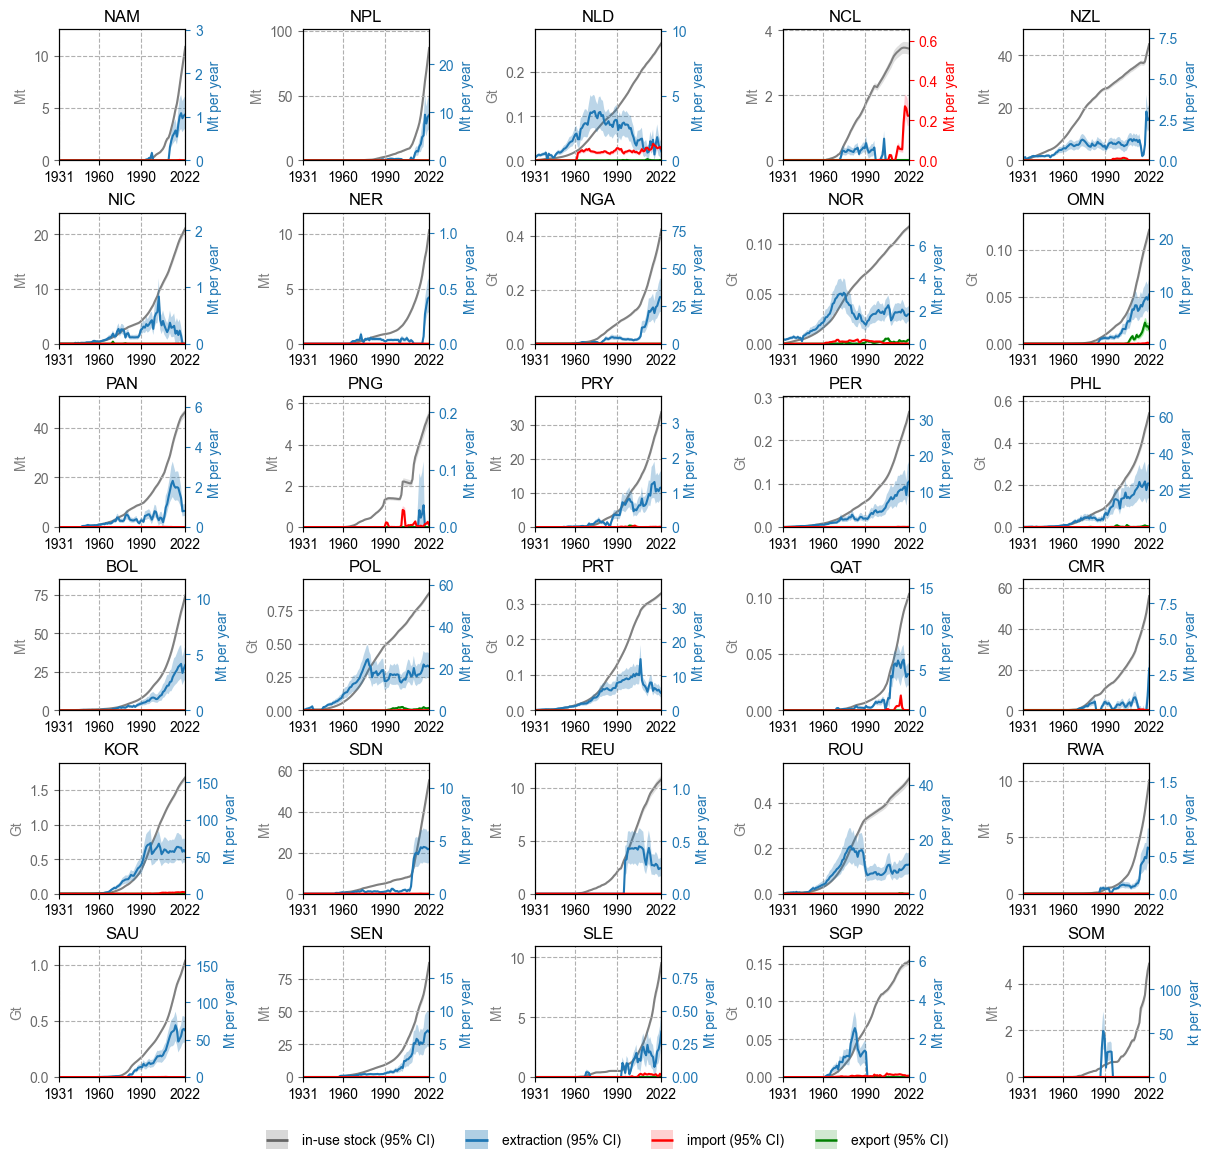

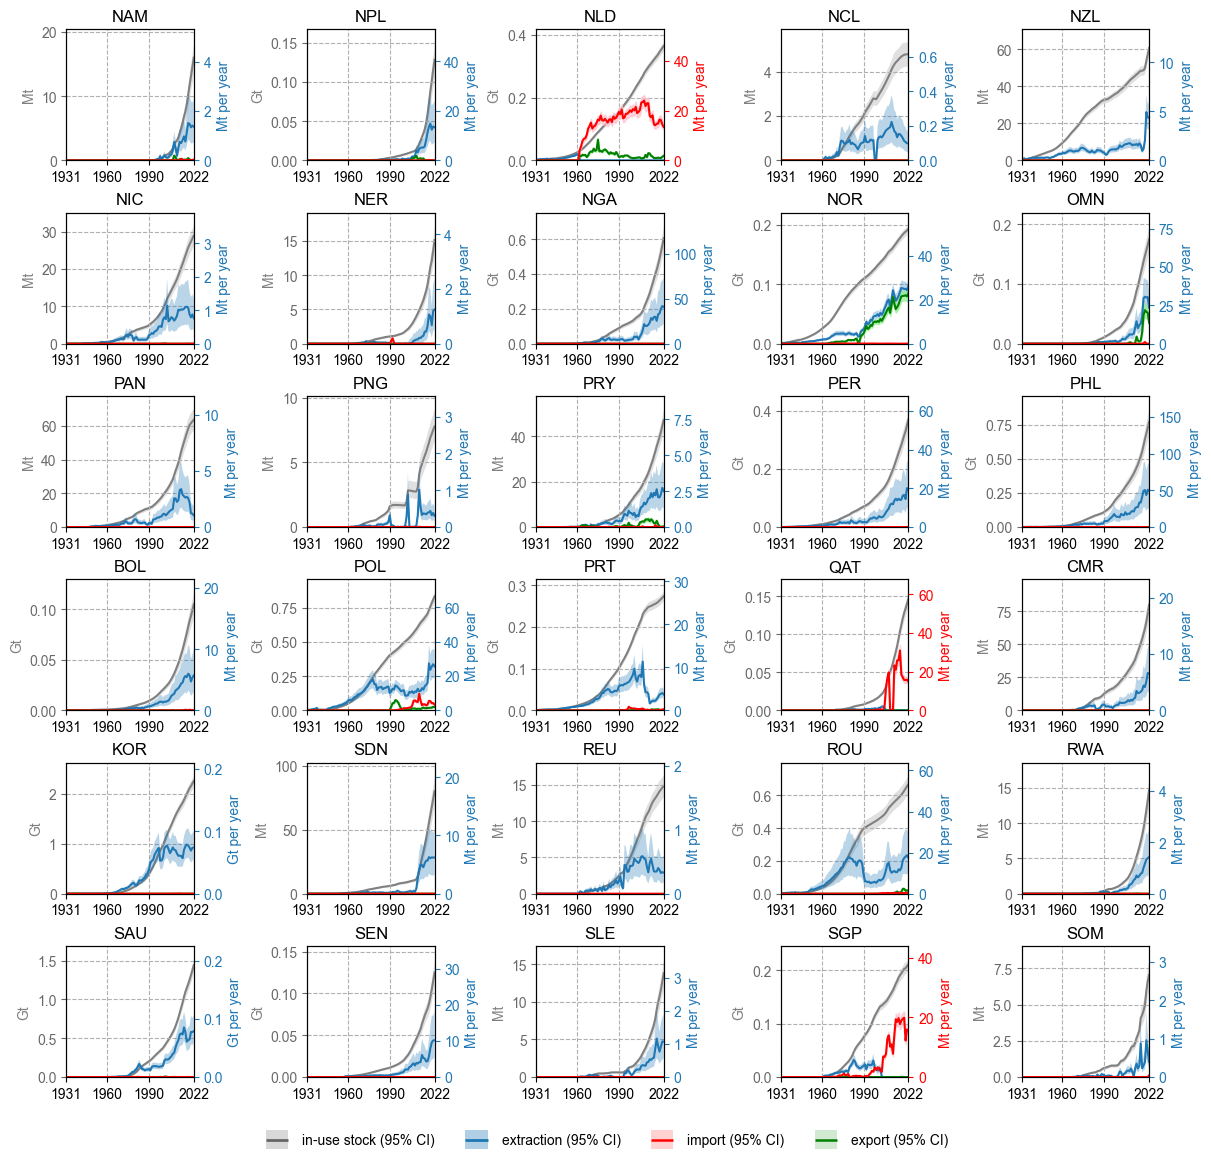

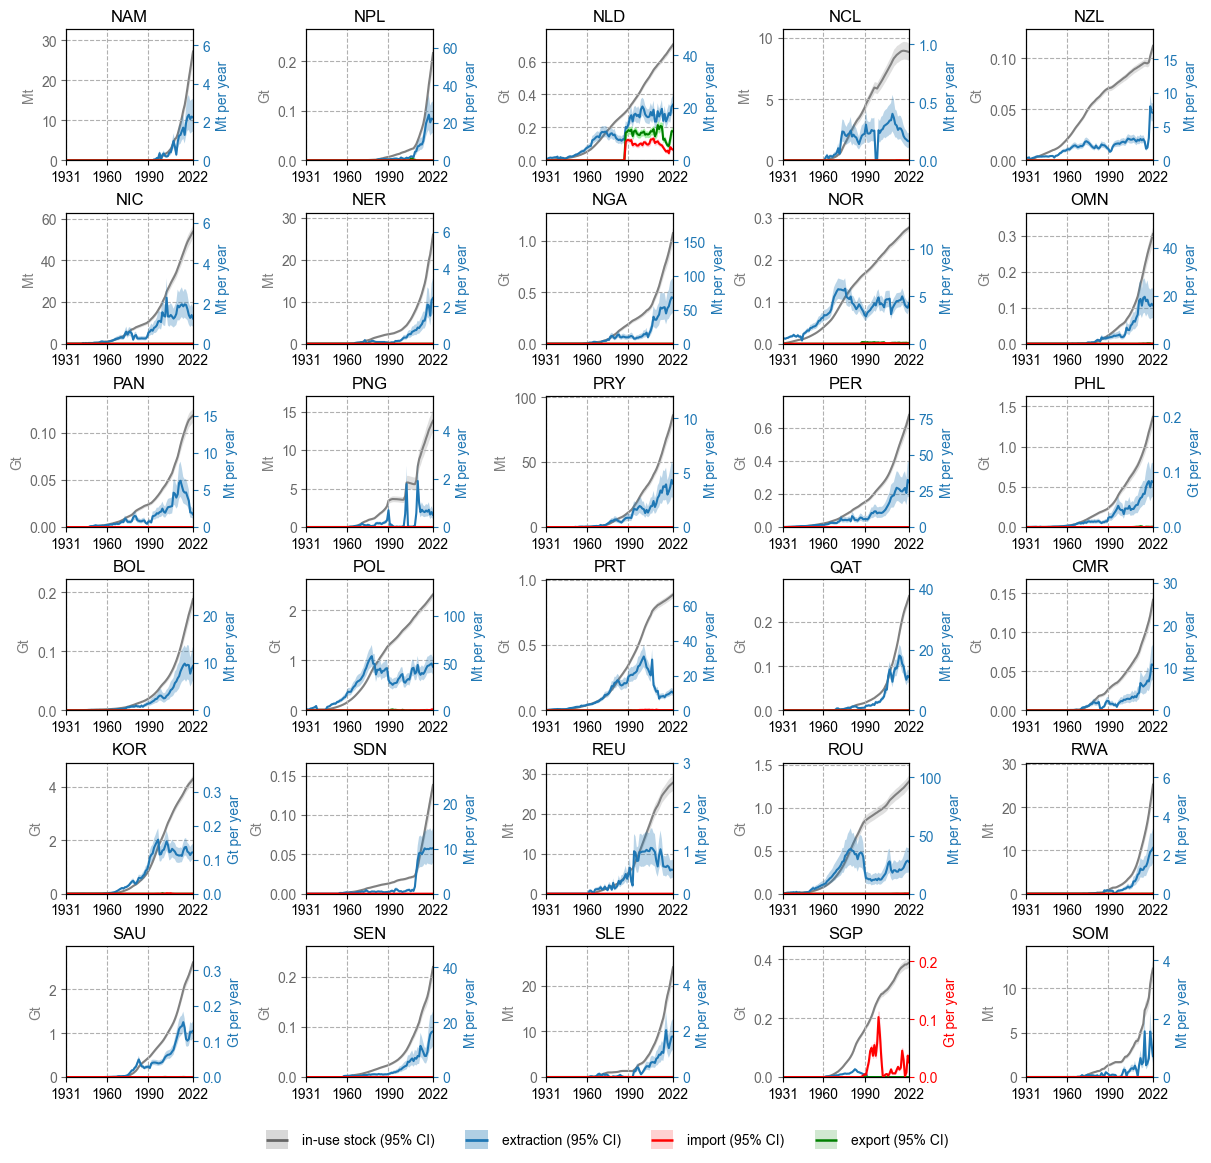

 80%|████████  | 4/5 [01:10<00:17, 17.56s/it]

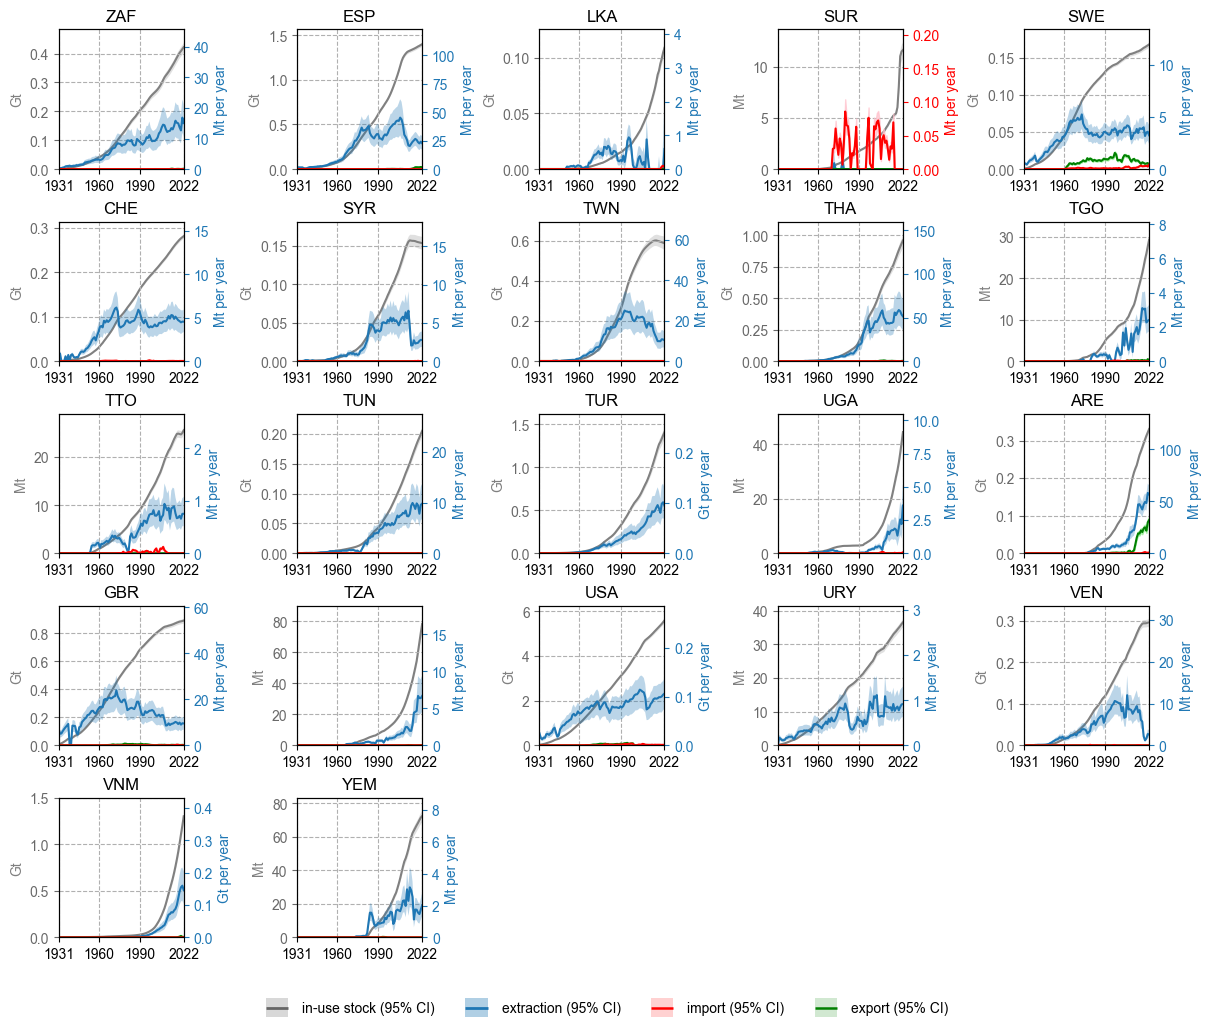

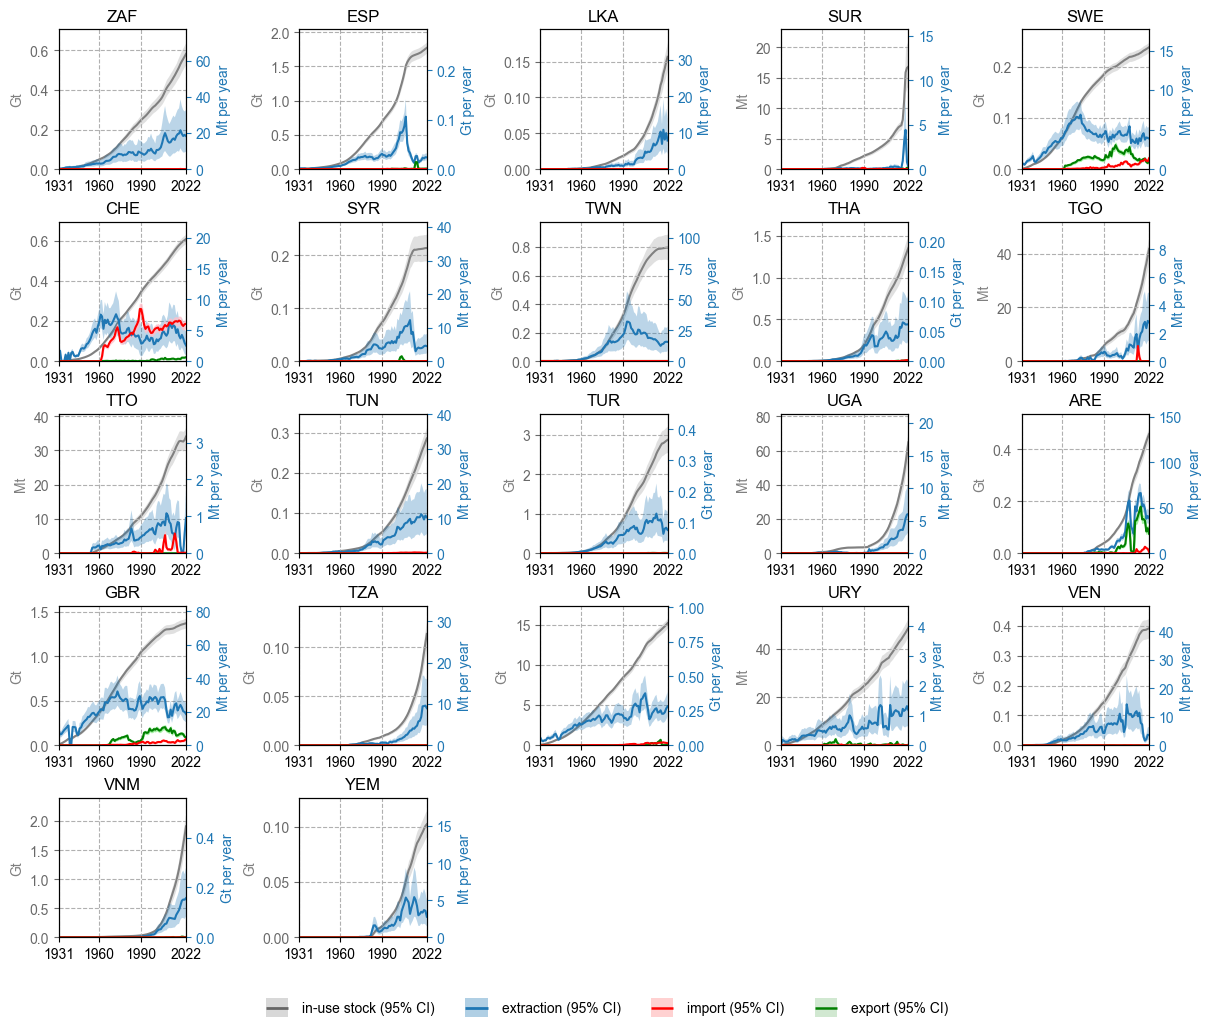

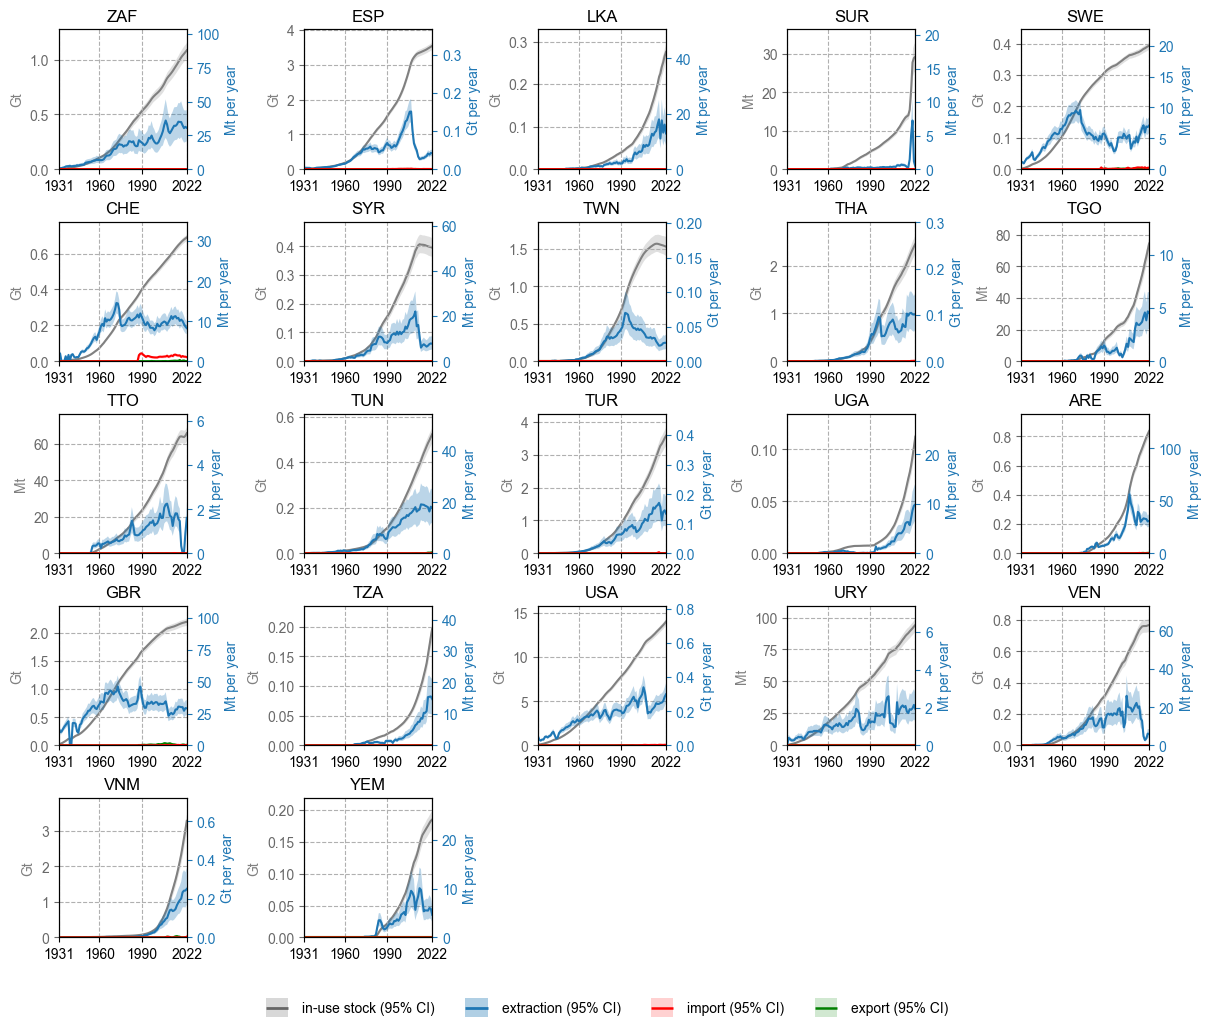

100%|██████████| 5/5 [01:23<00:00, 16.75s/it]


: 

In [ ]:
for j in tqdm(range(5)):
    for material in ['limestone', 'gravel', 'sand']: 
        fig = plt.figure(figsize=(12, 11), constrained_layout=True)
        plt.rcParams['font.family'] = 'Arial' 
        for i, country in enumerate(economies_142[j*30:(j+1)*30]):
            axx = plt.subplot(6, 5, i+1)
            draw_historical_for_a_country(material, country, axx)

        fig.legend(handles, labels,
            handler_map={tuple: HandlerLineWithBand(band_scale=2)},  # 调粗细：0.7~1.0
            loc='lower center', bbox_to_anchor=(0.5, -.05 if j != 4 else .07), 
            ncol=4, frameon=False)

        plt.show()
        output_path = os.path.join('..', 'figures', f'supplementary-figure-historical-{material}-{j+1}.jpg')
        fig.savefig(output_path, dpi=600, bbox_inches='tight')
